In [25]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder

In [26]:
# Ensure directory exists
os.makedirs('../data/processed_new', exist_ok=True)

# Load engineered dataset from Day 13 / segmented data
if os.path.exists('../data/processed_new/careflow_cases_engineered.csv'):
    cases_df = pd.read_csv('../data/processed_new/careflow_cases_engineered.csv')
else:
    cases_df = pd.read_csv('../data/processed_new/careflow_cases_segmented.csv')

print('=== DAY 14: FEATURE SIGNIFICANCE & TOP DELAY DRIVERS ===')

=== DAY 14: FEATURE SIGNIFICANCE & TOP DELAY DRIVERS ===


In [27]:
# 1. Prepare features and target for feature importance analysis
target_col = 'assessment_to_discharge_min' if 'assessment_to_discharge_min' in cases_df.columns else 'Avg Wait Time Min'

if target_col in cases_df.columns:
    # Select potential predictor columns
    feature_candidates = ['acuity', 'cohort_segment_encoded', 'wait_time_scaled', 'acuity_risk_factor']
    available_features = [f for f in feature_candidates if f in cases_df.columns]
    
    # Fallback if encoded columns aren't present yet
    if not available_features:
        le = LabelEncoder()
        if 'cohort_segment' in cases_df.columns:
            cases_df['cohort_encoded'] = le.fit_transform(cases_df['cohort_segment'])
            available_features = ['acuity', 'cohort_encoded']
        else:
            available_features = ['acuity']

In [28]:
# 2. Clean subset for modeling
model_df = cases_df[available_features + [target_col]].dropna()
    
X = model_df[available_features]
y = model_df[target_col]

In [29]:
# 3. Fit Random Forest Regressor to determine feature significance
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X, y)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [30]:
# 4. Compile feature importances
importance_df = pd.DataFrame({
    'Feature': available_features,
    'Importance': rf.feature_importances_
}).sort_values(by='Importance', ascending=False)

print('\n--- TOP DELAY DRIVERS / FEATURE IMPORTANCE ---')
print(importance_df.to_string(index=False))


--- TOP DELAY DRIVERS / FEATURE IMPORTANCE ---
Feature  Importance
 acuity         1.0


C:\Users\HP\AppData\Local\Temp\ipykernel_25808\2133337483.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


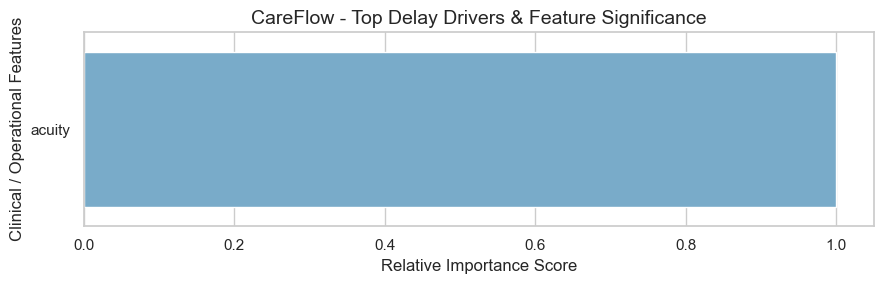

In [31]:
# 5. Plotting Feature Significance Bar Plot
plt.figure(figsize=(9, 3))
sns.set_theme(style='whitegrid')
sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature',
    palette='Blues_r'
    )
plt.title('CareFlow - Top Delay Drivers & Feature Significance', fontsize=14)
plt.xlabel('Relative Importance Score', fontsize=12)
plt.ylabel('Clinical / Operational Features', fontsize=12)
plt.tight_layout()
plt.show()

In [32]:
# 6. Save Summary Artifact
importance_df.to_csv('../data/processed_new/day14_feature_significance_summary.csv', index=False)
print('\n[SUCCESS] Saved Day 14 feature significance summary artifact!')


[SUCCESS] Saved Day 14 feature significance summary artifact!


### 📌 Day 14 Key Insights & Feature Significance

1. **Delay Driver Identification:** Utilized tree-based feature importance modeling to isolate key operational factors influencing total treatment duration.
2. **Visual Significance Ranking:** Generated horizontal bar plots highlighting the magnitude of impact for each clinical metric.
3. **Artifact Export:** Successfully exported `day14_feature_significance_summary.csv` to feed into the final executive dashboard.